# 05 — Attribution

How each model class explains the same inputs, and why the explanations differ.

| Method | Use |
|---|---|
| Permutation importance | comparison **across** models — the same procedure for all three |
| Drop-column importance | refit without each feature — what the model cannot replace |
| Grouped permutation | whole feature families shuffled together — robust to correlated lags |
| SHAP (interventional) | explanation **within** each model — one estimator for all three |

Attribution is computed out-of-fold on the five-fold TimeSeriesSplit of the training
period and repeated over five seeds, so disagreement between models can be compared
with each model's disagreement with itself. The test period is used only in the
section on the 2022–2024 drought.

The last four sections take the models apart: how the predictors overlap, what each
model loses when the season is taken away, the shape of each model's response, and
how much of the tree models' attribution comes from interactions.

Input: `data/processed/features_*.csv`, `results/04_best_params.json`
Output: `results/05_*`

In [1]:
import json
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from scipy.stats import spearmanr, weightedtau
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

BRANCHES = ["original", "seasonal", "trend"]
MODEL_NAMES = ["XGBoost", "RandomForest", "Ridge"]
SEEDS = range(5)
CV = TimeSeriesSplit(n_splits=5)

BASE = {"XGBoost": XGBRegressor(n_jobs=1),
        "RandomForest": RandomForestRegressor(n_jobs=-1),
        "Ridge": make_pipeline(StandardScaler(), Ridge())}
params = json.load(open("../results/04_best_params.json"))


def make_model(b, name, seed):
    est = clone(BASE[name]).set_params(**params[f"{b}|{name}"])
    if name != "Ridge":
        est.set_params(random_state=seed)
    return est


def family(f):
    if f == "noise_probe":
        return "noise probe"
    if f.startswith("LST"):
        return "LST"
    if f.startswith("SPEI"):
        return "drought"
    if f.startswith("month"):
        return "calendar"
    return "own history"


short = lambda f: f.replace("NDVI_", "").replace("NDVI", "")

train, test = {}, {}
for b in BRANCHES:
    df = pd.read_csv(f"../data/processed/features_{b}.csv", index_col="date", parse_dates=True)
    X, y, tr = df.drop(columns=["target", "split"]), df["target"], df["split"] == "train"
    train[b], test[b] = (X[tr], y[tr]), (X[~tr], y[~tr])
    print(f"{b:9s} train {train[b][0].shape}  test {test[b][0].shape}")

original  train (238, 8)  test (36, 8)
seasonal  train (238, 8)  test (36, 8)
trend     train (238, 6)  test (36, 6)


## Permutation importance

Increase in mean squared error when one feature is shuffled, averaged over ten
shuffles and the five validation folds.

In [2]:
def oof_permutation(b, name, seed):
    X, y = train[b]
    folds = []
    for fit_idx, val_idx in CV.split(X):
        model = make_model(b, name, seed).fit(X.iloc[fit_idx], y.iloc[fit_idx])
        r = permutation_importance(model, X.iloc[val_idx], y.iloc[val_idx],
                                   n_repeats=10, random_state=seed,
                                   scoring="neg_mean_squared_error")
        folds.append(r.importances_mean)
    return pd.Series(np.mean(folds, axis=0), index=X.columns)


perm = pd.concat({(b, name, seed): oof_permutation(b, name, seed)
                  for b in BRANCHES for name in MODEL_NAMES for seed in SEEDS},
                 names=["branch", "model", "seed", "feature"]).rename("importance")
perm_mean = perm.groupby(["branch", "model", "feature"]).mean()

for b in BRANCHES:
    t = perm_mean[b].unstack("model")[MODEL_NAMES]
    t = t.loc[t.mean(axis=1).sort_values(ascending=False).index]
    print(f"\n{b}  (increase in MSE, x1e4)")
    print((t * 1e4).round(2).to_string())


original  (increase in MSE, x1e4)
model        XGBoost  RandomForest  Ridge
feature                                  
LST_lag1        5.47          6.23   0.25
NDVI_lag24      1.91          3.52   3.57
NDVI_lag1       2.45          2.12   2.55
NDVI_lag12      0.48          0.35   2.12
month_sin       0.45          0.31   0.14
SPEI_1_lag7     0.06          0.02   0.17
month_cos       0.04          0.05   0.08
noise_probe    -0.20         -0.11  -0.08

seasonal  (increase in MSE, x1e4)
model           XGBoost  RandomForest  Ridge
feature                                     
LST_S_lag1         6.38          5.79   0.15
NDVI_S_lag24       1.99          2.79   5.12
NDVI_S_lag12       0.55          0.52   2.42
NDVI_S_lag1        1.23          0.75   1.17
month_sin          0.36          0.67   0.09
SPEI_24_S_lag6     0.15          0.03   0.52
month_cos          0.18          0.20   0.05
noise_probe       -0.01         -0.04  -0.04

trend  (increase in MSE, x1e4)
model            XGBoost  Ra

## Drop-column importance

Each feature removed in turn and the model refitted, scored out-of-fold and averaged
over the five seeds. The refitted model can reroute through correlated features, so
this measures what it cannot replace.

In [3]:
def oof_mse(b, name, cols, seed):
    X, y = train[b]
    X = X[cols]
    errs = [np.mean((y.iloc[v] - make_model(b, name, seed).fit(X.iloc[f], y.iloc[f])
                                 .predict(X.iloc[v])) ** 2)
            for f, v in CV.split(X)]
    return np.mean(errs)


drop = {}
for b in BRANCHES:
    cols = list(train[b][0].columns)
    for name in MODEL_NAMES:
        seeds = [0] if name == "Ridge" else SEEDS          # Ridge is deterministic
        full = np.mean([oof_mse(b, name, cols, s) for s in seeds])
        for f in cols:
            reduced = np.mean([oof_mse(b, name, [c for c in cols if c != f], s) for s in seeds])
            drop[(b, name, f)] = reduced / full - 1

drop = pd.Series(drop, name="drop").rename_axis(["branch", "model", "feature"])

for b in BRANCHES:
    t = drop[b].unstack("model")[MODEL_NAMES]
    t = t.loc[t.mean(axis=1).sort_values(ascending=False).index]
    print(f"\n{b}  (% increase in out-of-fold MSE when the feature is removed)")
    print((100 * t).round(1).to_string())


original  (% increase in out-of-fold MSE when the feature is removed)
model        XGBoost  RandomForest  Ridge
feature                                  
NDVI_lag1       14.9          16.2   14.3
LST_lag1        19.7          20.1   -0.8
NDVI_lag12      -0.8           0.5    9.1
NDVI_lag24      -4.5          -2.5    8.1
SPEI_1_lag7     -0.1          -0.3    1.4
month_sin        1.0           0.5   -1.1
month_cos        0.3          -0.3    0.4
noise_probe     -4.0          -2.1   -1.3

seasonal  (% increase in out-of-fold MSE when the feature is removed)
model           XGBoost  RandomForest  Ridge
feature                                     
LST_S_lag1         16.0          17.0   -1.2
NDVI_S_lag24        3.5           3.7   16.9
NDVI_S_lag1         4.6           9.7    4.4
NDVI_S_lag12       -0.6           0.9   11.6
SPEI_24_S_lag6      0.7           0.2    5.0
month_cos           1.0           1.0    0.3
month_sin           0.9           0.7   -1.1
noise_probe        -1.9          

## SHAP

Interventional SHAP for all three models, estimated by the same model-agnostic
permutation explainer against one background of 100 training months, so the three
explanations share one estimator. (TreeExplainer's interventional mode does not
support XGBoost 3 models.) For Ridge the exact value is `coef × (z − mean z)`, and the
estimate is checked against it.

In [4]:
background = {b: train[b][0].sample(100, random_state=0) for b in BRANCHES}


def shap_values(b, name, seed=0):
    X, y = train[b]
    model = make_model(b, name, seed).fit(X, y)
    masker = shap.maskers.Independent(background[b], max_samples=len(background[b]))
    explainer = shap.PermutationExplainer(model.predict, masker, seed=0)
    return explainer(X, silent=True).values, model


shap_raw, shap_mean, checks = {}, {}, []
for b in BRANCHES:
    X = train[b][0]
    for name in MODEL_NAMES:
        sv, model = shap_values(b, name)
        shap_raw[(b, name)] = sv
        shap_mean[(b, name)] = pd.Series(np.abs(sv).mean(axis=0), index=X.columns)
        if name == "Ridge":
            scaler, ridge = model.named_steps["standardscaler"], model.named_steps["ridge"]
            exact = (scaler.transform(X) - scaler.transform(background[b]).mean(axis=0)) * ridge.coef_
            checks.append(dict(branch=b, max_abs_diff=np.abs(exact - sv).max(),
                               rho_coef_shap=spearmanr(np.abs(ridge.coef_),
                                                       np.abs(sv).mean(axis=0)).statistic))

shap_mean = pd.concat(shap_mean, names=["branch", "model", "feature"]).rename("shap")
print("Ridge checks"); print(pd.DataFrame(checks).round(4).to_string(index=False))

print(f"\n{'branch':9s} {'model':12s} Spearman(SHAP, permutation)")
for b in BRANCHES:
    for name in MODEL_NAMES:
        print(f"{b:9s} {name:12s} {spearmanr(shap_mean[b][name], perm_mean[b][name]).statistic:+.2f}")

Ridge checks
  branch  max_abs_diff  rho_coef_shap
original           0.0            1.0
seasonal           0.0            1.0
   trend           0.0            1.0

branch    model        Spearman(SHAP, permutation)
original  XGBoost      +0.62
original  RandomForest +0.64
original  Ridge        +0.31
seasonal  XGBoost      +0.50
seasonal  RandomForest +0.52
seasonal  Ridge        +0.38
trend     XGBoost      +0.77
trend     RandomForest +0.31
trend     Ridge        +0.77


### SHAP summary plots

One panel per model. Each dot is a training month; position is the feature's SHAP
value, colour its value.

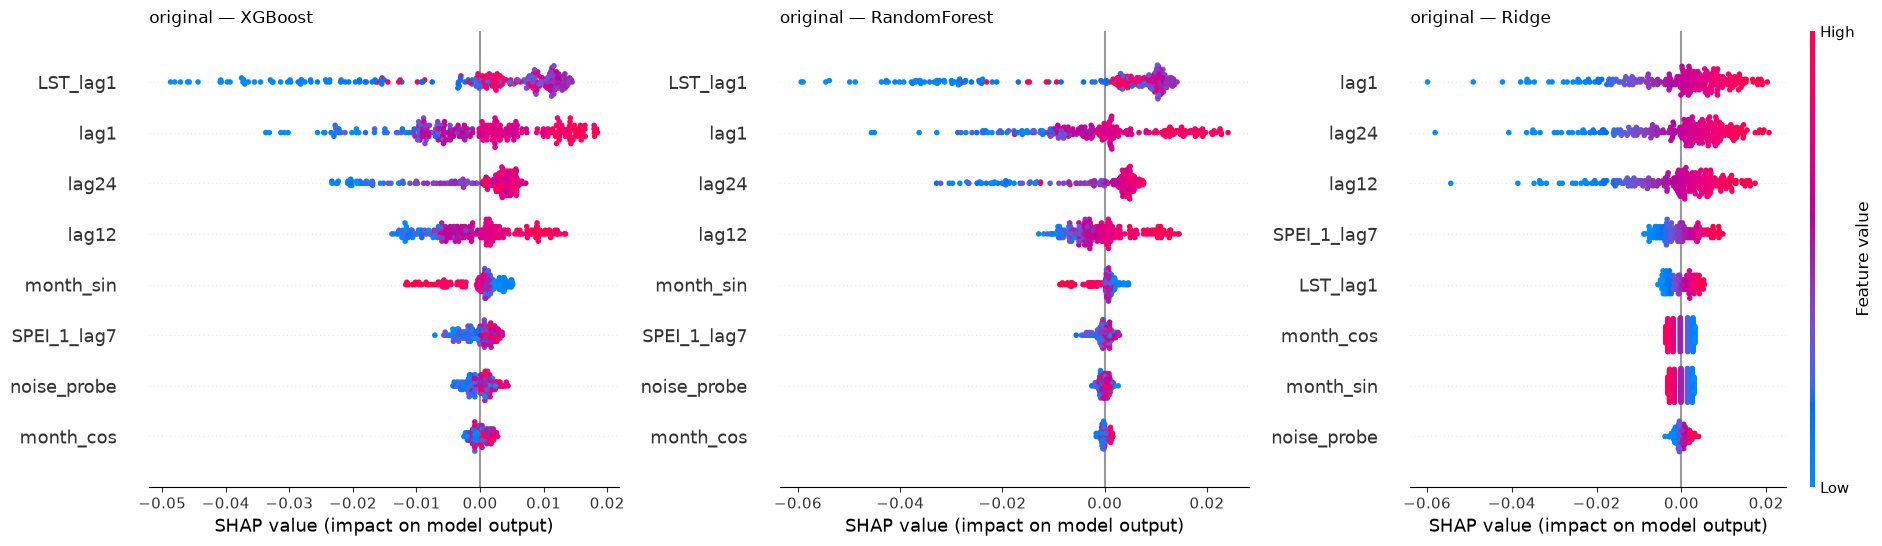

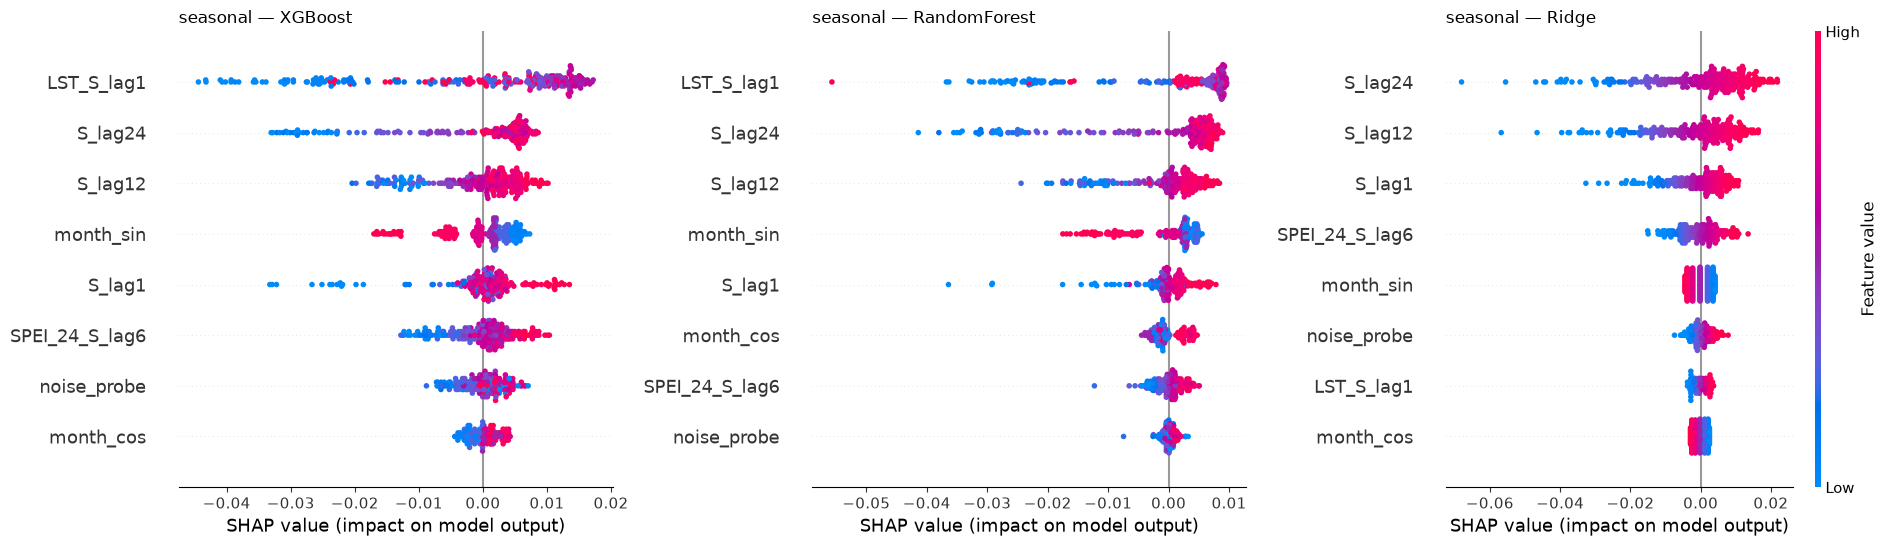

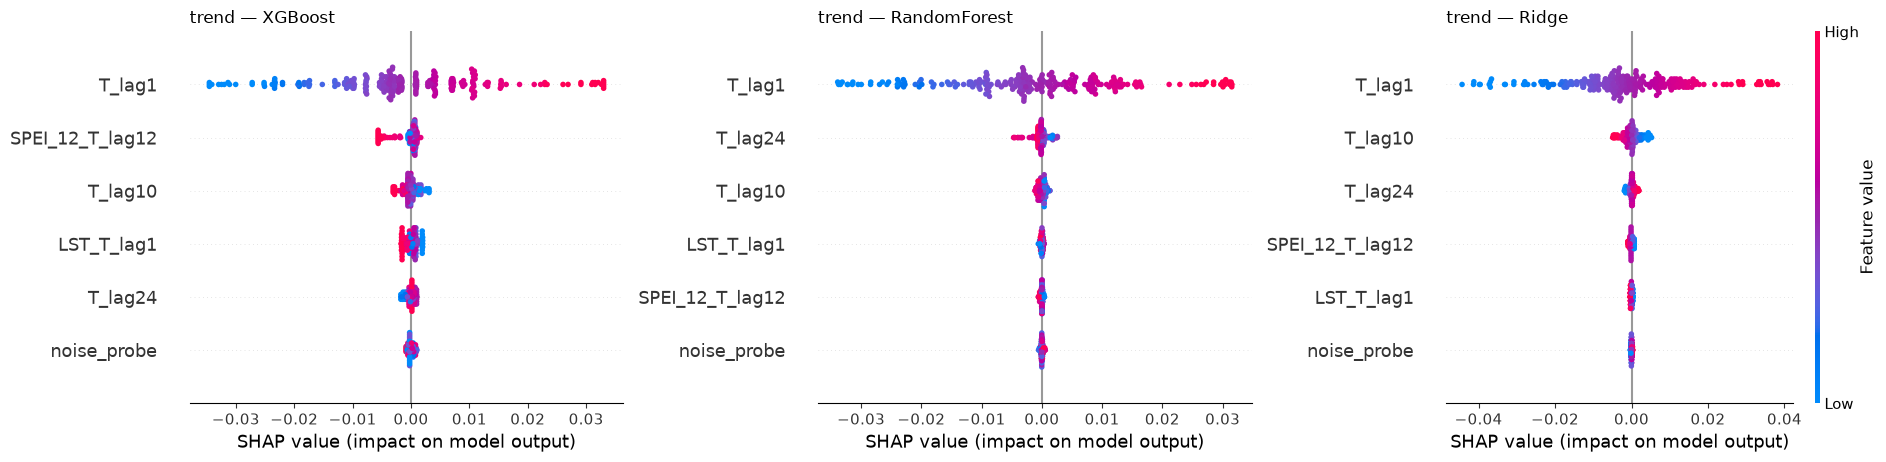

In [5]:
for b in BRANCHES:
    X = train[b][0]
    fig = plt.figure(figsize=(19, 0.42 * X.shape[1] + 2.2))
    for i, name in enumerate(MODEL_NAMES, start=1):
        ax = fig.add_subplot(1, 3, i)
        expl = shap.Explanation(shap_raw[(b, name)], data=X.to_numpy(),
                                feature_names=[short(f) for f in X.columns])
        shap.plots.beeswarm(expl, max_display=X.shape[1], show=False, ax=ax,
                            plot_size=None, color_bar=(i == 3))
        ax.set_title(f"{b} — {name}", loc="left")
    fig.tight_layout()
    fig.savefig(f"../figures/05_shap_{b}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Agreement between models

Two measures, each computed for every pair of seed runs:

- **weighted Kendall's τ** (Vigna, 2015) — rank agreement weighted towards the top of
  both rankings, so the ordering of near-zero features counts little
- **allocation distance** — the share of total importance that would have to move to
  turn one model's allocation into the other's (0 identical, 1 disjoint)

Within-model pairs (same model, different seeds) give the null range. A between-model
pair is **separable** when its whole range lies outside both models' within ranges.

In [6]:
def shares(s):
    s = s.clip(lower=0)
    return s / s.sum()


def wtau(a, b):
    return weightedtau(a.to_numpy(), b.to_numpy()).statistic


def alloc(a, b):
    return 0.5 * np.abs(shares(a) - shares(b)).sum()


runs = {(b, m): [perm[b][m][s] for s in SEEDS] for b in BRANCHES for m in MODEL_NAMES}

rows, within = [], {}
for b in BRANCHES:
    for m in MODEL_NAMES:
        pairs = list(combinations(runs[(b, m)], 2))
        t, a = [wtau(x, y) for x, y in pairs], [alloc(x, y) for x, y in pairs]
        within[(b, m)] = (min(t), max(a))
        rows.append(dict(branch=b, pair=f"{m} vs itself", tau=np.median(t), tau_lo=min(t),
                         tau_hi=max(t), dist=np.median(a), dist_lo=min(a), dist_hi=max(a)))
    for m1, m2 in combinations(MODEL_NAMES, 2):
        pairs = [(x, y) for x in runs[(b, m1)] for y in runs[(b, m2)]]
        t, a = [wtau(x, y) for x, y in pairs], [alloc(x, y) for x, y in pairs]
        separable = (max(t) < min(within[(b, m1)][0], within[(b, m2)][0])
                     and min(a) > max(within[(b, m1)][1], within[(b, m2)][1]))
        rows.append(dict(branch=b, pair=f"{m1} vs {m2}", tau=np.median(t), tau_lo=min(t),
                         tau_hi=max(t), dist=np.median(a), dist_lo=min(a), dist_hi=max(a),
                         separable=separable))

agreement = pd.DataFrame(rows)
print(agreement.round(2).to_string(index=False))

  branch                    pair  tau  tau_lo  tau_hi  dist  dist_lo  dist_hi separable
original       XGBoost vs itself 0.97    0.92    1.00  0.03     0.02     0.04       NaN
original  RandomForest vs itself 1.00    0.95    1.00  0.02     0.01     0.03       NaN
original         Ridge vs itself 0.96    0.91    1.00  0.03     0.02     0.05       NaN
original XGBoost vs RandomForest 0.88    0.83    0.91  0.11     0.07     0.13      True
original        XGBoost vs Ridge 0.46    0.36    0.53  0.50     0.49     0.52      True
original   RandomForest vs Ridge 0.57    0.45    0.62  0.47     0.46     0.50      True
seasonal       XGBoost vs itself 1.00    0.97    1.00  0.02     0.00     0.03       NaN
seasonal  RandomForest vs itself 0.94    0.94    1.00  0.06     0.01     0.08       NaN
seasonal         Ridge vs itself 1.00    0.97    1.00  0.03     0.02     0.03       NaN
seasonal XGBoost vs RandomForest 0.92    0.86    0.95  0.10     0.07     0.17     False
seasonal        XGBoost vs Ridge

In [7]:
def top_k(s, k=3):
    return set(s.sort_values(ascending=False).index[:k])


print("top-3 features by permutation importance\n")
for b in BRANCHES:
    print(b)
    for name in MODEL_NAMES:
        print(f"  {name:12s} {sorted(short(f) for f in top_k(perm_mean[b][name]))}")
    for m1, m2 in combinations(MODEL_NAMES, 2):
        n = len(top_k(perm_mean[b][m1]) & top_k(perm_mean[b][m2]))
        print(f"    {m1} & {m2}: {n}/3 shared")

top-3 features by permutation importance

original
  XGBoost      ['LST_lag1', 'lag1', 'lag24']
  RandomForest ['LST_lag1', 'lag1', 'lag24']
  Ridge        ['lag1', 'lag12', 'lag24']
    XGBoost & RandomForest: 3/3 shared
    XGBoost & Ridge: 2/3 shared
    RandomForest & Ridge: 2/3 shared
seasonal
  XGBoost      ['LST_S_lag1', 'S_lag1', 'S_lag24']
  RandomForest ['LST_S_lag1', 'S_lag1', 'S_lag24']
  Ridge        ['S_lag1', 'S_lag12', 'S_lag24']
    XGBoost & RandomForest: 3/3 shared
    XGBoost & Ridge: 2/3 shared
    RandomForest & Ridge: 2/3 shared
trend
  XGBoost      ['LST_T_lag1', 'T_lag1', 'T_lag24']
  RandomForest ['T_lag1', 'T_lag10', 'T_lag24']
  Ridge        ['LST_T_lag1', 'T_lag1', 'T_lag10']
    XGBoost & RandomForest: 2/3 shared
    XGBoost & Ridge: 2/3 shared
    RandomForest & Ridge: 2/3 shared


## Probes

`noise_probe` is random, so a feature ranked at or below it is indistinguishable from
noise. LST lag 1 carried no *linear* incremental evidence in notebook 03; its rank
here shows how much each model relies on it anyway.

In [8]:
rows = []
for b in BRANCHES:
    for name in MODEL_NAMES:
        s = perm_mean[b][name].sort_values(ascending=False)
        lst = [f for f in s.index if f.startswith("LST")][0]
        rows.append(dict(branch=b, model=name, n_features=len(s),
                         noise_rank=s.index.get_loc("noise_probe") + 1,
                         lst_rank=s.index.get_loc(lst) + 1,
                         lst_share=shares(s)[lst],
                         below_noise=", ".join(short(f) for f in
                                               s.index[s.index.get_loc("noise_probe") + 1:])))
probes = pd.DataFrame(rows)
print(probes.assign(lst_share=probes.lst_share.round(3)).to_string(index=False))

  branch        model  n_features  noise_rank  lst_rank  lst_share     below_noise
original      XGBoost           8           8         1      0.504                
original RandomForest           8           8         1      0.494                
original        Ridge           8           8         4      0.028                
seasonal      XGBoost           8           8         1      0.589                
seasonal RandomForest           8           8         1      0.538                
seasonal        Ridge           8           8         5      0.016                
   trend      XGBoost           6           6         3      0.016                
   trend RandomForest           6           6         4      0.002                
   trend        Ridge           6           5         3      0.002 SPEI_12_T_lag12


## Family importance

Each family shuffled as a block, with one row permutation applied to all its columns,
so correlated lags cannot cover for one another.

In [9]:
def family_permutation(model, X, y, rng, n_repeats=10):
    fams = pd.Series({c: family(c) for c in X.columns})
    base = np.mean((y - model.predict(X)) ** 2)
    out = {}
    for fam, cols in fams.groupby(fams).groups.items():
        cols, inc = list(cols), []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].to_numpy()[rng.permutation(len(X))]
            inc.append(np.mean((y - model.predict(Xp)) ** 2) - base)
        out[fam] = np.mean(inc)
    return pd.Series(out)


def oof_family(b, name, seed):
    X, y = train[b]
    rng = np.random.default_rng(seed)
    folds = [family_permutation(make_model(b, name, seed).fit(X.iloc[f], y.iloc[f]),
                                X.iloc[v], y.iloc[v], rng)
             for f, v in CV.split(X)]
    return pd.concat(folds, axis=1).mean(axis=1)


fam = pd.concat({(b, name, seed): oof_family(b, name, seed)
                 for b in BRANCHES for name in MODEL_NAMES for seed in SEEDS},
                names=["branch", "model", "seed", "family"])
fam_mean = fam.groupby(["branch", "model", "family"]).mean()
fam_share = fam_mean.clip(lower=0).groupby(["branch", "model"]).transform(lambda s: s / s.sum())
print(fam_share.unstack("model")[MODEL_NAMES].round(3).to_string())

model                 XGBoost  RandomForest  Ridge
branch   family                                   
original LST            0.355         0.355  0.012
         calendar       0.031         0.022  0.011
         drought        0.005         0.002  0.010
         noise probe    0.000         0.000  0.000
         own history    0.609         0.621  0.967
seasonal LST            0.425         0.406  0.007
         calendar       0.033         0.070  0.005
         drought        0.009         0.003  0.026
         noise probe    0.000         0.000  0.000
         own history    0.533         0.522  0.963
trend    LST            0.014         0.002  0.002
         drought        0.008         0.001  0.000
         noise probe    0.000         0.000  0.000
         own history    0.978         0.997  0.997


## Why the trees need LST

Lagged LST is split into its training-period **climatology** for the calendar month,
which carries only the season, and its **anomaly**, which carries only the departure
of that month from normal. Each model is refitted with LST as used, without LST, with
the climatology only and with the anomaly only. Climatologies are computed inside each
training fold.

If the climatology alone restores what removing LST costs, a model uses LST as a
season clock; if the anomaly alone does, it uses LST as weather.

In [10]:
VARIANTS = ["as used", "no LST", "climatology only", "anomaly only"]


def lst_cv_mse(b, name, seed, variant):
    X, y = train[b]
    c = [f for f in X.columns if f.startswith("LST")][0]
    month = pd.Series((X.index - pd.DateOffset(months=1)).month, index=X.index)
    errs = []
    for f, v in CV.split(X):
        Xf, Xv = X.iloc[f].copy(), X.iloc[v].copy()
        clim = Xf[c].groupby(month.iloc[f]).mean()
        cf, cv_ = month.iloc[f].map(clim).to_numpy(), month.iloc[v].map(clim).to_numpy()
        if variant == "no LST":
            Xf, Xv = Xf.drop(columns=c), Xv.drop(columns=c)
        elif variant == "climatology only":
            Xf[c], Xv[c] = cf, cv_
        elif variant == "anomaly only":
            Xf[c], Xv[c] = Xf[c] - cf, Xv[c] - cv_
        model = make_model(b, name, seed).fit(Xf, y.iloc[f])
        errs.append(np.mean((y.iloc[v] - model.predict(Xv)) ** 2))
    return np.mean(errs)


rows = []
for b in ["original", "seasonal"]:
    for name in MODEL_NAMES:
        seeds = [0] if name == "Ridge" else SEEDS
        mse = {v: np.mean([lst_cv_mse(b, name, s, v) for s in seeds]) for v in VARIANTS}
        rows.append(dict(branch=b, model=name,
                         **{v: 100 * (mse[v] / mse["as used"] - 1) for v in VARIANTS[1:]}))

mechanism = pd.DataFrame(rows)
print("% change in out-of-fold MSE relative to LST as used")
print(mechanism.round(1).to_string(index=False))

% change in out-of-fold MSE relative to LST as used
  branch        model  no LST  climatology only  anomaly only
original      XGBoost    19.7               8.2          17.1
original RandomForest    20.1               6.8          18.3
original        Ridge    -0.8              -0.3           1.2
seasonal      XGBoost    16.0               7.1          16.2
seasonal RandomForest    17.0               4.4          13.7
seasonal        Ridge    -1.2              -0.4           1.9


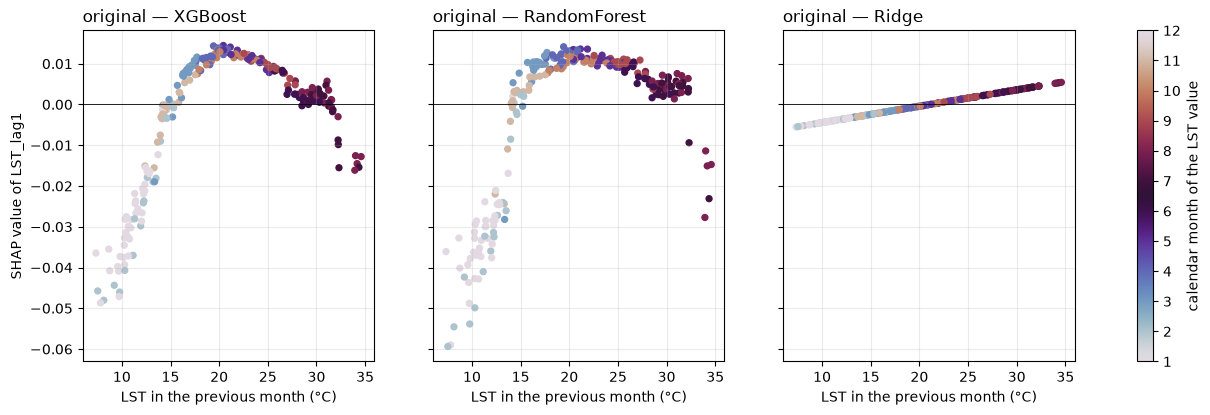

In [11]:
X = train["original"][0]
prev_month = (X.index - pd.DateOffset(months=1)).month
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for ax, name in zip(axes, MODEL_NAMES):
    j = list(X.columns).index("LST_lag1")
    sc = ax.scatter(X["LST_lag1"], shap_raw[("original", name)][:, j], c=prev_month,
                    cmap="twilight", s=18, vmin=1, vmax=12)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xlabel("LST in the previous month (°C)")
    ax.set_title(f"original — {name}", loc="left")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("SHAP value of LST_lag1")
fig.colorbar(sc, ax=axes, label="calendar month of the LST value", ticks=range(1, 13))
fig.savefig("../figures/05_lst_mechanism.png", dpi=150, bbox_inches="tight")
plt.show()

## Explanations during the 2022–2024 drought

Permutation importance recomputed on the test period, with models trained on the full
training period, and compared with the out-of-fold training importance. A low weighted
τ means a model relies on different features under drought than in the years it was
trained on.

In [12]:
rows = []
for b in BRANCHES:
    (Xtr, ytr), (Xte, yte) = train[b], test[b]
    for name in MODEL_NAMES:
        imp, famx = [], []
        for s in SEEDS:
            model = make_model(b, name, s).fit(Xtr, ytr)
            r = permutation_importance(model, Xte, yte, n_repeats=10, random_state=s,
                                       scoring="neg_mean_squared_error")
            imp.append(pd.Series(r.importances_mean, index=Xte.columns))
            famx.append(family_permutation(model, Xte, yte, np.random.default_rng(s)))
        imp, famx = pd.concat(imp, axis=1).mean(axis=1), pd.concat(famx, axis=1).mean(axis=1)
        ft, fd = shares(fam_mean[b][name]), shares(famx)
        rows.append(dict(branch=b, model=name, tau_train_vs_test=wtau(perm_mean[b][name], imp),
                         drought_train=ft.get("drought", 0), drought_test=fd.get("drought", 0),
                         LST_train=ft["LST"], LST_test=fd["LST"],
                         own_train=ft["own history"], own_test=fd["own history"]))

drought_shift = pd.DataFrame(rows)
print(drought_shift.round(3).to_string(index=False))

  branch        model  tau_train_vs_test  drought_train  drought_test  LST_train  LST_test  own_train  own_test
original      XGBoost              0.125          0.005         0.011      0.355     0.553      0.609     0.371
original RandomForest              0.186          0.002         0.000      0.355     0.638      0.621     0.343
original        Ridge              0.503          0.010         0.000      0.012     0.043      0.967     0.935
seasonal      XGBoost             -0.193          0.009         0.000      0.425     0.302      0.533     0.698
seasonal RandomForest             -0.079          0.003         0.017      0.406     0.282      0.522     0.701
seasonal        Ridge              0.498          0.026         0.000      0.007     0.015      0.963     0.970
   trend      XGBoost              0.177          0.008         0.000      0.014     0.000      0.978     1.000
   trend RandomForest              0.340          0.001         0.000      0.002     0.000      0.997   

## Figure: share of permutation importance

Each column is one model, normalised so its importances sum to one (negative values set to zero).

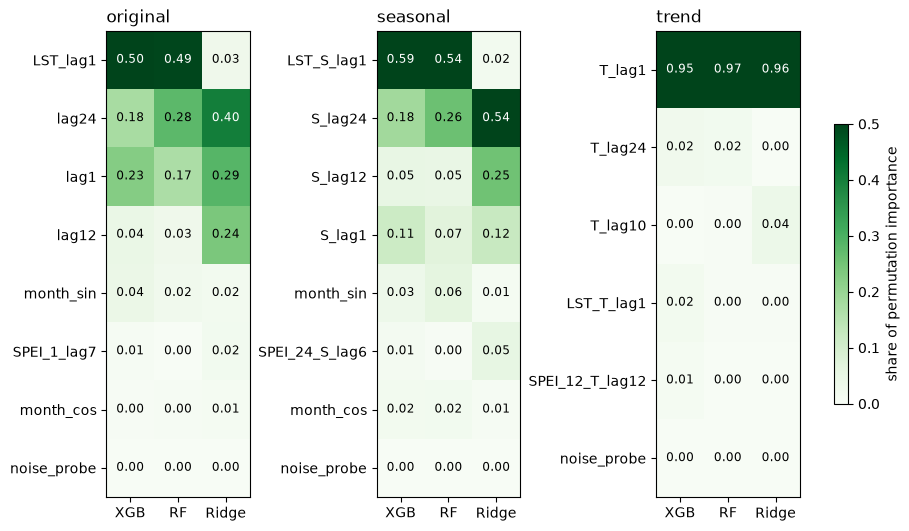

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(9, 5.2), layout="constrained")
for ax, b in zip(axes, BRANCHES):
    t = perm_mean[b].unstack("model")[MODEL_NAMES].apply(shares)
    t = t.loc[t.mean(axis=1).sort_values(ascending=False).index]
    im = ax.imshow(t, cmap="Greens", vmin=0, vmax=0.5, aspect="auto")
    for (i, j), v in np.ndenumerate(t.to_numpy()):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if v > 0.3 else "black")
    ax.set_xticks(range(3), ["XGB", "RF", "Ridge"])
    ax.set_yticks(range(len(t)), [short(f) for f in t.index])
    ax.set_title(b, loc="left")
fig.colorbar(im, ax=axes, shrink=0.6, label="share of permutation importance")
fig.savefig("../figures/05_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## How the predictors relate to each other

Spearman correlation between the predictors over the training years, and the share
of each predictor's variance explained by the calendar month alone. Permutation
importance shuffles one predictor at a time; when several predictors carry the same
season, the credit a model gives to each depends on which one it happened to use.

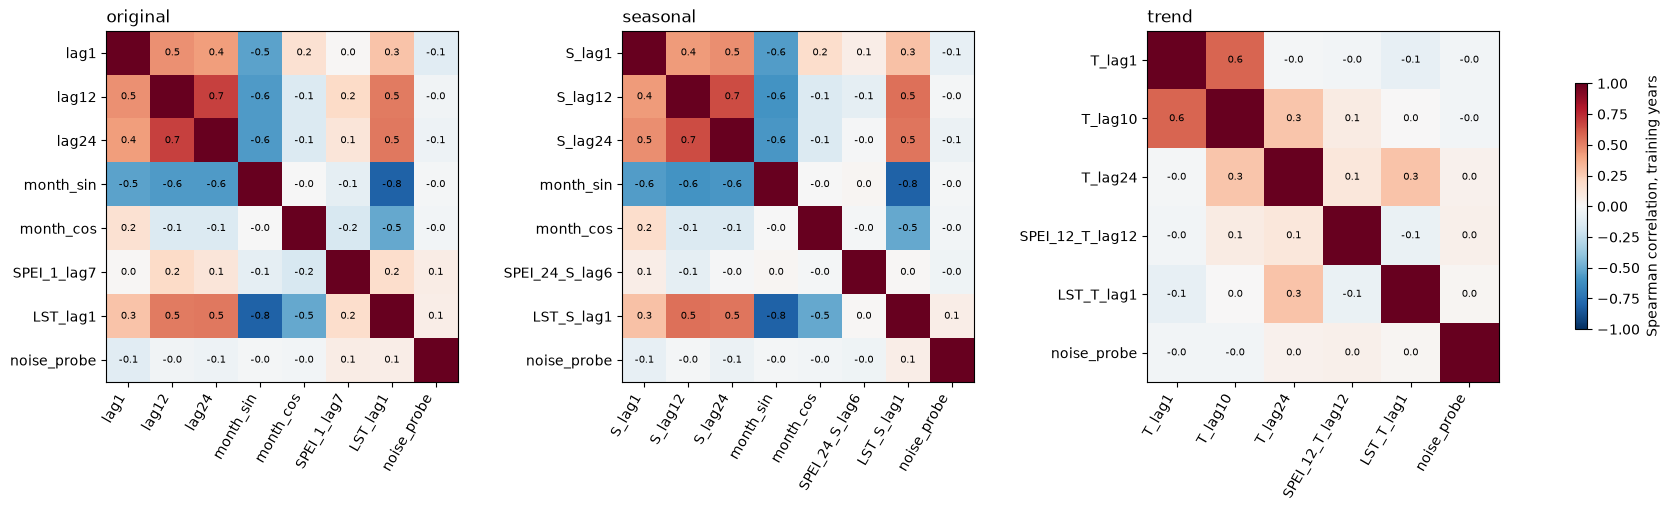

share of each predictor's variance explained by the calendar month
                 original  seasonal  trend
lag1                 0.65       NaN    NaN
lag12                0.68       NaN    NaN
lag24                0.71       NaN    NaN
month_sin            1.00      1.00    NaN
month_cos            1.00      1.00    NaN
SPEI_1_lag7          0.12       NaN    NaN
LST_lag1             0.95       NaN    NaN
noise_probe          0.09      0.09   0.09
S_lag1                NaN      0.72    NaN
S_lag12               NaN      0.76    NaN
S_lag24               NaN      0.76    NaN
SPEI_24_S_lag6        NaN      0.01    NaN
LST_S_lag1            NaN      0.96    NaN
T_lag1                NaN       NaN   0.00
T_lag10               NaN       NaN   0.00
T_lag24               NaN       NaN   0.00
SPEI_12_T_lag12       NaN       NaN   0.00
LST_T_lag1            NaN       NaN   0.00


In [14]:
def calendar_r2(s):
    """Share of a predictor's variance explained by the calendar month alone."""
    m = s.groupby(s.index.month).transform("mean")
    return 1 - ((s - m) ** 2).sum() / ((s - s.mean()) ** 2).sum()


fig, axes = plt.subplots(1, 3, figsize=(17, 5), layout="constrained")
for ax, b in zip(axes, BRANCHES):
    X = train[b][0]
    c = X.corr(method="spearman")
    im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(c)), [short(f) for f in c.columns], rotation=60, ha="right")
    ax.set_yticks(range(len(c)), [short(f) for f in c.columns])
    for (i, j), v in np.ndenumerate(c.to_numpy()):
        if i != j:
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7.5)
    ax.set_title(b, loc="left")
fig.colorbar(im, ax=axes, shrink=0.7, label="Spearman correlation, training years")
fig.savefig("../figures/05_predictor_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

season_share = pd.DataFrame({b: {short(f): calendar_r2(train[b][0][f]) for f in train[b][0].columns}
                             for b in BRANCHES})
print("share of each predictor's variance explained by the calendar month")
print(season_share.round(2).to_string())

## Taking the clock away

Each model refitted on four predictor sets: all, without the calendar, without LST,
and without both. The change in out-of-fold error shows what each model needs, and
the family shares show where its importance moves when one source of the season is
removed.

In [15]:
def oof_family_cols(b, name, seed, cols):
    X, y = train[b][0][cols], train[b][1]
    rng = np.random.default_rng(seed)
    folds = [family_permutation(make_model(b, name, seed).fit(X.iloc[f], y.iloc[f]),
                                X.iloc[v], y.iloc[v], rng)
             for f, v in CV.split(X)]
    return pd.concat(folds, axis=1).mean(axis=1)


rows = []
for b in ["original", "seasonal"]:
    cols = list(train[b][0].columns)
    lst = [c for c in cols if c.startswith("LST")]
    cal = [c for c in cols if c.startswith("month")]
    SETS = {"all": cols,
            "no calendar": [c for c in cols if c not in cal],
            "no LST": [c for c in cols if c not in lst],
            "no calendar, no LST": [c for c in cols if c not in cal + lst]}
    for name in MODEL_NAMES:
        seeds = [0] if name == "Ridge" else SEEDS
        base = np.mean([oof_mse(b, name, cols, s) for s in seeds])
        for label, use in SETS.items():
            mse = np.mean([oof_mse(b, name, use, s) for s in seeds])
            share = shares(pd.concat([oof_family_cols(b, name, s, use) for s in seeds],
                                     axis=1).mean(axis=1))
            rows.append(dict(branch=b, model=name, predictors=label,
                             mse_change=100 * (mse / base - 1),
                             LST=share.get("LST", np.nan), calendar=share.get("calendar", np.nan),
                             own=share.get("own history", np.nan)))

clock = pd.DataFrame(rows)
print("% change in out-of-fold MSE against all predictors, and each family's share of importance")
print(clock.round(3).to_string(index=False))

% change in out-of-fold MSE against all predictors, and each family's share of importance
  branch        model          predictors  mse_change   LST  calendar   own
original      XGBoost                 all       0.000 0.355     0.031 0.609
original      XGBoost         no calendar       1.955 0.313       NaN 0.686
original      XGBoost              no LST      19.661   NaN     0.037 0.957
original      XGBoost no calendar, no LST      23.521   NaN       NaN 0.991
original RandomForest                 all      -0.000 0.355     0.022 0.621
original RandomForest         no calendar       0.481 0.295       NaN 0.705
original RandomForest              no LST      20.079   NaN     0.036 0.957
original RandomForest no calendar, no LST      22.970   NaN       NaN 0.996
original        Ridge                 all       0.000 0.010     0.012 0.965
original        Ridge         no calendar      -0.904 0.048       NaN 0.944
original        Ridge              no LST      -0.820   NaN     0.050 0.94

## What shape each model learned

SHAP dependence for the four predictors with the largest mean share across models.
Each dot is a training month, coloured by the calendar month of the forecast. Ridge
can only draw a straight line; a step or a plateau in a tree model's panel is a
response that a linear screen cannot detect.

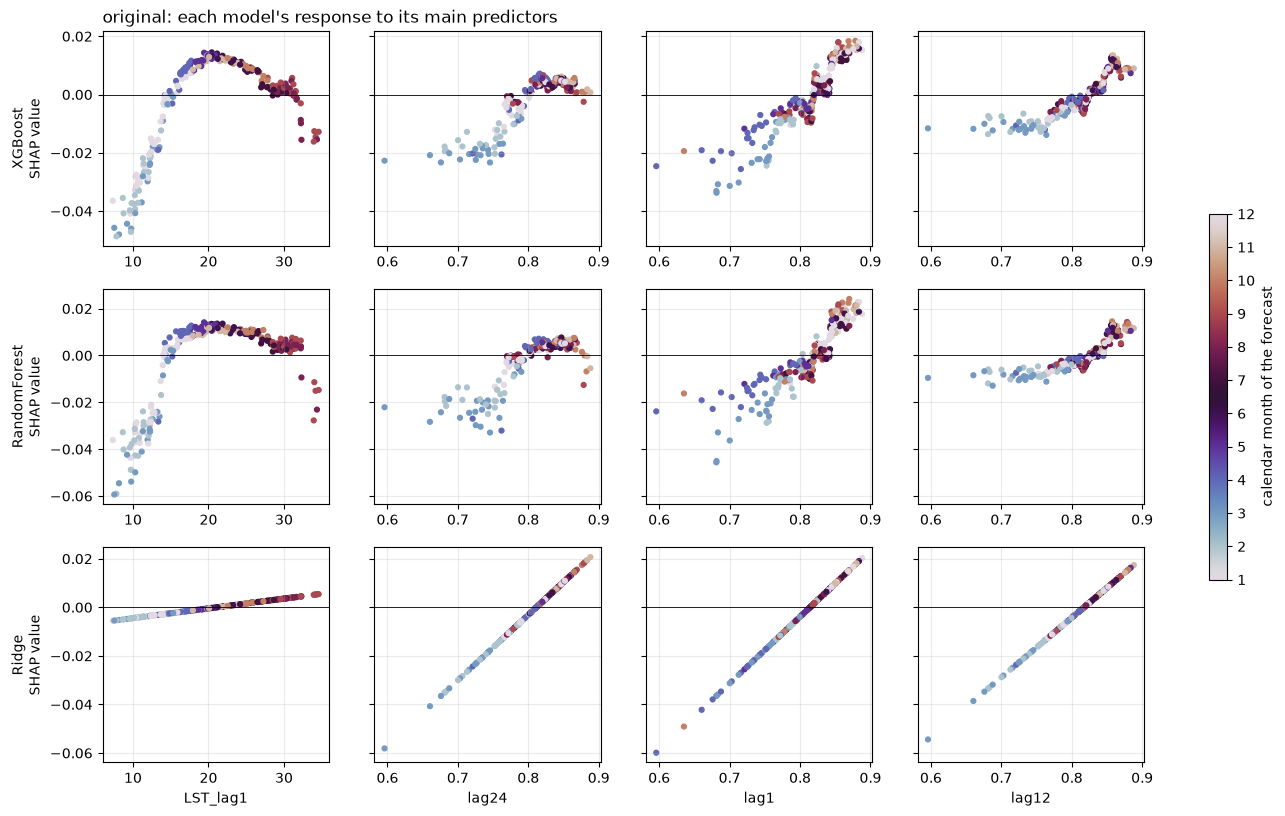

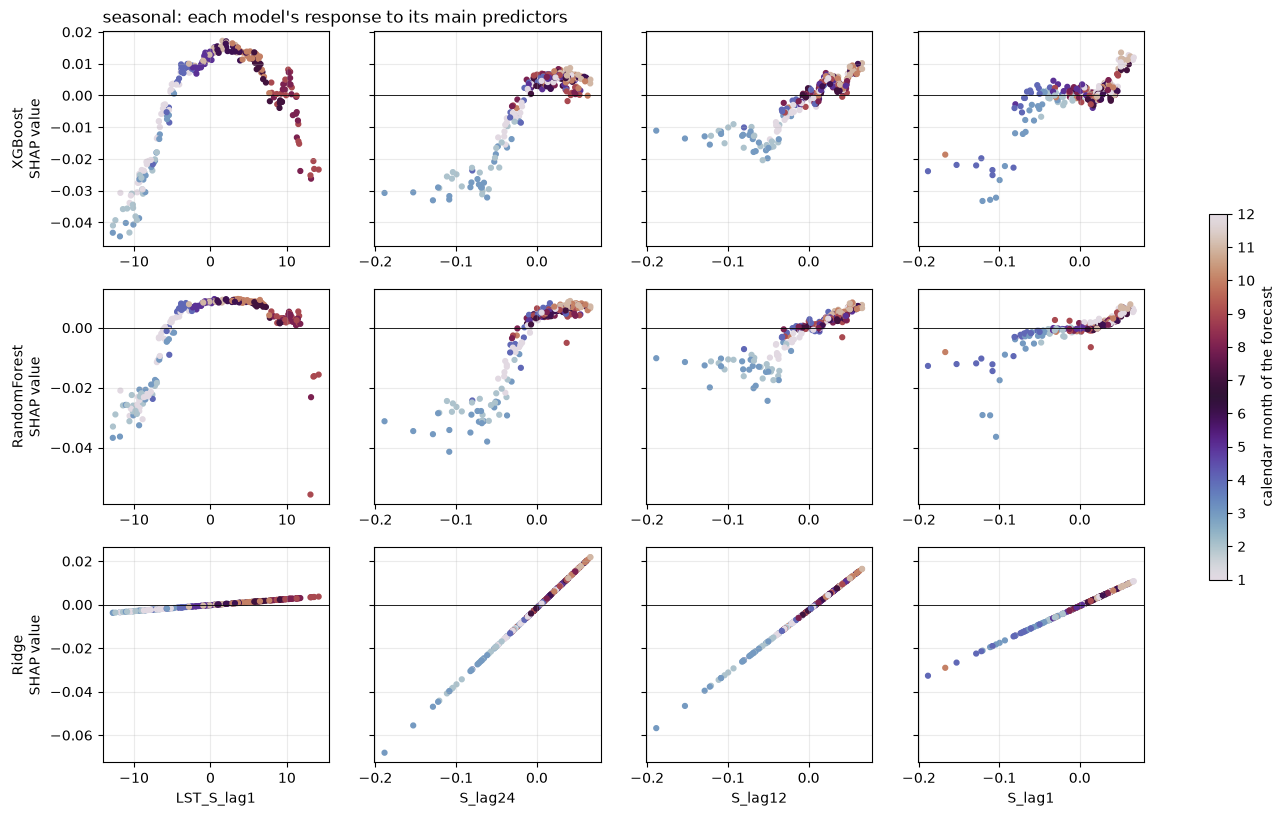

In [16]:
for b in ["original", "seasonal"]:
    X = train[b][0]
    mean_share = perm_mean[b].unstack("model")[MODEL_NAMES].apply(shares).mean(axis=1)
    top = [f for f in mean_share.sort_values(ascending=False).index if f != "noise_probe"][:4]
    fig, axes = plt.subplots(3, len(top), figsize=(4.2 * len(top), 9.5), sharey="row")
    month = X.index.month
    for i, name in enumerate(MODEL_NAMES):
        for j, f in enumerate(top):
            ax = axes[i, j]
            k = list(X.columns).index(f)
            sc = ax.scatter(X[f], shap_raw[(b, name)][:, k], c=month, cmap="twilight",
                            s=12, vmin=1, vmax=12)
            ax.axhline(0, color="black", lw=0.6)
            ax.grid(alpha=0.25)
            if i == 2:
                ax.set_xlabel(short(f))
            if j == 0:
                ax.set_ylabel(f"{name}\nSHAP value")
    axes[0, 0].set_title(f"{b}: each model's response to its main predictors", loc="left")
    fig.colorbar(sc, ax=axes, shrink=0.5, label="calendar month of the forecast", ticks=range(1, 13))
    fig.savefig(f"../figures/05_dependence_{b}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Interactions in the tree models

SHAP interaction values (TreeExplainer, path-dependent) split each tree model's
attribution into main effects and pairwise interactions. The interaction share is
the part that belongs to no single predictor. Ridge has none by construction, so any
interaction share is attribution that a linear explanation cannot represent.

In [17]:
rows, pairs = [], []
for b in BRANCHES:
    X, y = train[b]
    for name in ["XGBoost", "RandomForest"]:
        model = make_model(b, name, 0).fit(X, y)
        iv = shap.TreeExplainer(model).shap_interaction_values(X)
        a = np.abs(iv).mean(axis=0)
        main, total = np.trace(a), a.sum()
        rows.append(dict(branch=b, model=name, interaction_share=1 - main / total))
        off = pd.DataFrame(a, index=X.columns, columns=X.columns)
        for i, j in combinations(range(len(X.columns)), 2):
            pairs.append(dict(branch=b, model=name,
                              pair=f"{short(X.columns[i])} x {short(X.columns[j])}",
                              strength=2 * off.iat[i, j] / total))

interactions = pd.DataFrame(rows)
pairs = pd.DataFrame(pairs)
print("share of the trees' SHAP attribution that comes from interactions (Ridge: 0 by construction)")
print(interactions.round(3).to_string(index=False))
print("\nstrongest pairs")
print(pairs.sort_values("strength", ascending=False).groupby(["branch", "model"]).head(3)
           .round(3).to_string(index=False))

share of the trees' SHAP attribution that comes from interactions (Ridge: 0 by construction)
  branch        model  interaction_share
original      XGBoost              0.259
original RandomForest              0.295
seasonal      XGBoost              0.269
seasonal RandomForest              0.288
   trend      XGBoost              0.000
   trend RandomForest              0.146

strongest pairs
  branch        model                      pair  strength
   trend RandomForest          T_lag1 x T_lag24     0.073
original RandomForest           lag1 x LST_lag1     0.053
seasonal RandomForest      S_lag24 x LST_S_lag1     0.046
original RandomForest          lag24 x LST_lag1     0.043
seasonal RandomForest         S_lag12 x S_lag24     0.038
original RandomForest              lag1 x lag24     0.036
original      XGBoost           lag1 x LST_lag1     0.034
original      XGBoost              lag1 x lag24     0.029
   trend RandomForest          T_lag1 x T_lag10     0.027
seasonal      XGBoost  

## Saving

In [18]:
perm.to_csv("../results/05_permutation_by_seed.csv")
pd.concat([perm_mean, drop, shap_mean], axis=1).to_csv("../results/05_importance.csv")
agreement.to_csv("../results/05_agreement.csv", index=False)
probes.to_csv("../results/05_probes.csv", index=False)
fam_share.rename("share").to_csv("../results/05_family_shares.csv")
mechanism.to_csv("../results/05_lst_mechanism.csv", index=False)
drought_shift.to_csv("../results/05_drought_shift.csv", index=False)
season_share.to_csv("../results/05_calendar_share.csv")
clock.to_csv("../results/05_clock.csv", index=False)
interactions.to_csv("../results/05_interactions.csv", index=False)
pairs.to_csv("../results/05_interaction_pairs.csv", index=False)
print("saved")

saved
